# Chapter 3: Modeling with First-Order Differential Equations
## Complete Instructor Interactive Notebook

In [1]:
# Classroom setup — run once.
import base64
import importlib.util
import platform
import sys

_REQUIRED = ["numpy", "matplotlib", "scipy", "sympy", "ipywidgets"]
_missing = [name for name in _REQUIRED if importlib.util.find_spec(name) is None]

print(f"Python {sys.version.split()[0]} on {platform.system()}")
if _missing:
    print("Missing package(s):", ", ".join(_missing))
    print("Install with: python -m pip install -r requirements.txt")
else:
    print("Notebook environment is ready.")

import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

from scipy.integrate import solve_ivp
from IPython.display import display, Markdown, Math, clear_output
from matplotlib.patches import Rectangle, FancyArrowPatch

try:
    import ipywidgets as widgets
    from ipywidgets import ToggleButton, Output, VBox, Layout, FloatSlider, IntSlider, interact
    WIDGETS_AVAILABLE = True
except ImportError:
    WIDGETS_AVAILABLE = False

    def FloatSlider(*args, value=0.0, **kwargs):
        return value

    def IntSlider(*args, value=0, **kwargs):
        return value

    def interact(function, **kwargs):
        values = {key: getattr(obj, "value", obj) for key, obj in kwargs.items()}
        function(**values)
        return None

plt.rcParams["figure.figsize"] = (9, 5.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["font.size"] = 11

def safe_solve(rhs, t_span, y0, points=700, **kwargs):
    t_eval = np.linspace(t_span[0], t_span[1], points)
    return solve_ivp(rhs, t_span, y0, t_eval=t_eval, **kwargs)

def _reveal_button(encoded_answer, label="Reveal solution"):
    if not WIDGETS_AVAILABLE:
        display(Markdown(
            "**Reveal button unavailable.** Install `ipywidgets`, restart the kernel, "
            "and run this cell again."
        ))
        return

    button = ToggleButton(
        value=False,
        description=label,
        button_style="info",
        icon="eye",
        layout=Layout(width="190px", height="40px")
    )
    out = Output(layout=Layout(
        width="98%",
        border="1px solid #dddddd",
        padding="10px"
    ))

    def _toggle(change):
        with out:
            clear_output()
            if change["new"]:
                answer = base64.b64decode(encoded_answer).decode("utf-8")
                display(Markdown(answer))
                button.description = "Hide solution"
                button.icon = "eye-slash"
            else:
                button.description = label
                button.icon = "eye"

    button.observe(_toggle, names="value")
    display(VBox([button, out]))

def _show_problem(number, equation_latex, question_markdown, encoded_answer):
    display(Markdown(f"### Problem {number}"))
    if equation_latex:
        display(Math(r"\displaystyle " + equation_latex))
    if question_markdown:
        display(Markdown(question_markdown))
    _reveal_button(encoded_answer, label=f"Reveal #{number}")

def show_31_exit_check():
    _show_problem(
        1,
        r"A'=\text{rate in}-\text{rate out}",
        "A 200-L tank receives brine at 3 L/min with concentration 2 g/L and loses mixture at the same rate. Define the state variable, construct the differential equation, find the equilibrium salt amount, and state the modeling assumption used for the output concentration.",
        "IyMjIFNvbHV0aW9uCgpMZXQKCiQkCkEodCk9XHRleHR7Z3JhbXMgb2Ygc2FsdCBpbiB0aGUgdGFuayBhdCB0aW1lIH10LgokJAoKQmVjYXVzZSB0aGUgdm9sdW1lIHJlbWFpbnMgY29uc3RhbnQsCgokJApWPTIwMFx0ZXh0eyBMfS4KJCQKClRoZSBpbmZsb3cgc2FsdCByYXRlIGlzCgokJAooM1x0ZXh0eyBML21pbn0pKDJcdGV4dHsgZy9MfSkKPQo2XHRleHR7IGcvbWlufS4KJCQKClRoZSB3ZWxsLW1peGVkIGFzc3VtcHRpb24gZ2l2ZXMgdGhlIHRhbmsgY29uY2VudHJhdGlvbgoKJCQKXGZyYWN7QSh0KX17MjAwfVx0ZXh0eyBnL0x9LgokJAoKVGhlcmVmb3JlIHRoZSBvdXRmbG93IHNhbHQgcmF0ZSBpcwoKJCQKKDNcdGV4dHsgTC9taW59KVxsZWZ0KFxmcmFje0F9ezIwMH1cdGV4dHsgZy9MfVxyaWdodCkKPQpcZnJhY3szQX17MjAwfVx0ZXh0eyBnL21pbn0uCiQkCgpVc2luZwoKJCQKXHRleHR7cmF0ZSBvZiBjaGFuZ2V9PVx0ZXh0e3JhdGUgaW59LVx0ZXh0e3JhdGUgb3V0fSwKJCQKCndlIG9idGFpbgoKJCQKXGJveGVkewpBJz02LVxmcmFjezNBfXsyMDB9Lgp9CiQkCgpBdCBlcXVpbGlicml1bSwKCiQkCjA9Ni1cZnJhY3szQV4qfXsyMDB9LAokJAoKc28KCiQkClxib3hlZHtBXio9NDAwXHRleHR7IGd9Ln0KJCQKClRoZSBvdXRmbG93IGNvbmNlbnRyYXRpb24gaXMgdGFrZW4gdG8gYmUgJEEvMjAwJCBiZWNhdXNlIHRoZSB0YW5rIGlzIGFzc3VtZWQgdG8gYmUgcGVyZmVjdGx5IGFuZCBpbnN0YW50YW5lb3VzbHkgbWl4ZWQu"
    )

def show_32_exit_check():
    _show_problem(
        1,
        r"P'=0.6P\left(1-\frac{P}{900}\right)-h",
        "Find the maximum sustainable constant harvest and explain why this value is the threshold.",
        "IyMjIFNvbHV0aW9uCgpUaGUgdW5oYXJ2ZXN0ZWQgbG9naXN0aWMgZ3Jvd3RoIHRlcm0gaXMKCiQkCkcoUCk9MC42UFxsZWZ0KDEtXGZyYWN7UH17OTAwfVxyaWdodCkuCiQkCgpGb3IgYSBsb2dpc3RpYyBtb2RlbCwgdGhlIGdyb3d0aCByYXRlIGlzIG1heGltaXplZCBhdAoKJCQKUD1cZnJhY3tLfXsyfT1cZnJhY3s5MDB9ezJ9PTQ1MC4KJCQKClRoZSBtYXhpbXVtIGdyb3d0aCByYXRlIGlzCgokJApHX3tcbWF4fT1cZnJhY3tyS317NH0uCiQkCgpUaGVyZWZvcmUKCiQkCmhfe1xtYXh9Cj0KXGZyYWN7MC42KDkwMCl9ezR9Cj0KXGJveGVkezEzNX0uCiQkCgpUaHVzIHRoZSBsYXJnZXN0IGNvbnN0YW50IGhhcnZlc3QgdGhhdCBzdGlsbCBhbGxvd3MgYSBwb3NpdGl2ZSBlcXVpbGlicml1bSBpcwoKJCQKXGJveGVke2g9MTM1fQokJAoKcG9wdWxhdGlvbiB1bml0cyBwZXIgdW5pdCB0aW1lLg=="
    )

def show_33_exit_check():
    _show_problem(
        1,
        r"\begin{aligned}x'&=1.2x-0.08xy,\\ y'&=0.04xy-0.8y\end{aligned}",
        "Find the positive equilibrium and show how each equilibrium condition is obtained.",
        "IyMjIFNvbHV0aW9uCgpXcml0ZSB0aGUgc3lzdGVtIGluIGZhY3RvcmVkIGZvcm06CgokJAp4Jz14KDEuMi0wLjA4eSksCiQkCgokJAp5Jz15KDAuMDR4LTAuOCkuCiQkCgpGb3IgYSBwb3NpdGl2ZSBlcXVpbGlicml1bSwgd2UgcmVxdWlyZQoKJCQKeD4wLApccXF1YWQKeT4wLgokJAoKVGhlcmVmb3JlIHRoZSBmYWN0b3JzIGluIHBhcmVudGhlc2VzIG11c3QgdmFuaXNoOgoKJCQKMS4yLTAuMDh5PTAsCiQkCgphbmQKCiQkCjAuMDR4LTAuOD0wLgokJAoKU29sdmUgdGhlIGZpcnN0IGVxdWF0aW9uOgoKJCQKMC4wOHk9MS4yLAokJAoKc28KCiQkCnleKj1cZnJhY3sxLjJ9ezAuMDh9PTE1LgokJAoKU29sdmUgdGhlIHNlY29uZDoKCiQkCjAuMDR4PTAuOCwKJCQKCnNvCgokJAp4Xio9XGZyYWN7MC44fXswLjA0fT0yMC4KJCQKClRodXMgdGhlIHBvc2l0aXZlIGVxdWlsaWJyaXVtIGlzCgokJApcYm94ZWR7KHheKix5XiopPSgyMCwxNSkufQokJA=="
    )

Python 3.13.15 on Linux
Notebook environment is ready.


## Section 3.1: Linear Models

## 1. How a Differential Equation Becomes a Model

A differential equation is not automatically a useful model. Before writing an equation, we must decide what quantity is changing, why it is changing, and what assumptions allow us to describe those changes mathematically.

A **mathematical model** consists of:

- one or more **state variables** describing the quantities that change with time;
- **parameters** describing physical, biological, or empirical properties of the system;
- **initial conditions** specifying the starting state;
- a **rate law** or physical principle describing how the state changes;
- explicit **assumptions** that specify when the model is intended to apply.

For a first-order model, the basic question is

> What mechanisms increase or decrease the state variable?

A useful general balance principle is

$$
\boxed{
\frac{d}{dt}(\text{amount})
=
\text{rate in}
-
\text{rate out}
+
\text{rate produced}
-
\text{rate lost}.
}
$$

Every term in this equation must have the same physical units.

### Modeling Checklist

Before solving any application problem, identify the following:

$$
\renewcommand{\arraystretch}{1.5}
\begin{array}{|c|c|}
\hline
\textbf{Question} & \textbf{What to identify} \\
\hline
\text{What changes?} & \text{state variable and units} \\
\hline
\text{What is time?} & \text{independent variable and units} \\
\hline
\text{What controls the rate?} & \text{parameters and their units} \\
\hline
\text{Why does the quantity change?} & \text{physical or empirical rate law} \\
\hline
\text{When is the model valid?} & \text{assumptions and domain of validity} \\
\hline
\end{array}
$$

A differential equation with undefined variables or inconsistent units is not yet a complete model.

## 2. Exponential Growth and Decay

### Modeling assumption

Suppose $P(t)$ denotes a population or amount.

The simplest growth assumption is:

> The instantaneous rate of change is proportional to the amount currently present.

Mathematically,

$$
P'\propto P.
$$

Introducing a proportionality constant $k$ gives

$$
\boxed{
P'=kP.
}
$$

The units of $k$ must be inverse time. For example, if $t$ is measured in hours, then $k$ has units

$$
\text{hour}^{-1}.
$$

The sign of $k$ determines the direction of change:

- $k>0$: exponential growth;
- $k<0$: exponential decay;
- $k=0$: no change.

### Solving the model

Starting from

$$
\frac{dP}{dt}=kP,
$$

separate variables:

$$
\frac{dP}{P}=k\,dt.
$$

Integrate:

$$
\ln|P|=kt+C.
$$

Exponentiating and absorbing the constant gives

$$
P=Ce^{kt}.
$$

If

$$
P(0)=P_0,
$$

then

$$
P_0=C.
$$

Therefore

$$
\boxed{
P(t)=P_0e^{kt}.
}
$$

### Calibrating the parameter from data

Suppose a cell culture begins with

$$
P(0)=250
$$

cells and contains

$$
P(2)=350
$$

cells after two hours.

The model gives

$$
350=250e^{2k}.
$$

Divide by $250$:

$$
1.4=e^{2k}.
$$

Take the natural logarithm:

$$
\ln(1.4)=2k.
$$

Thus

$$
\boxed{
k=\frac{\ln(1.4)}{2}.
}
$$

Once $k$ has been estimated, the model can be used to predict the population at other times.

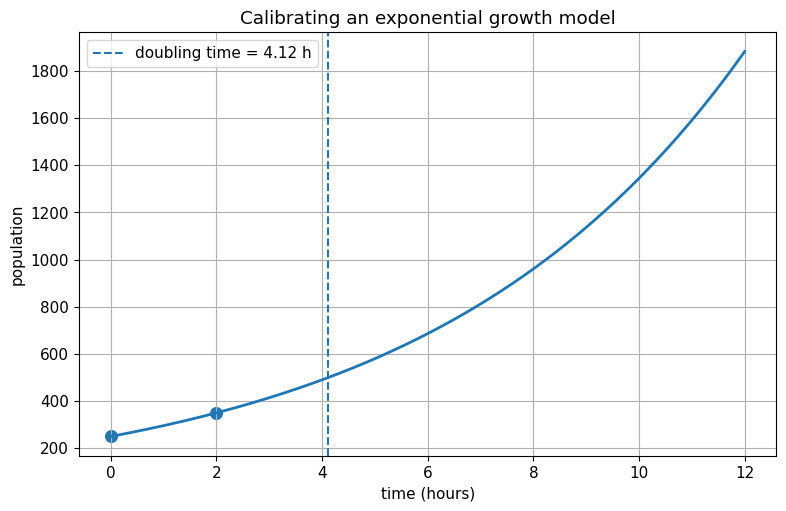

Estimated growth constant: 0.16823611831060645 per hour
Doubling time: 4.120085434212291 hours


In [2]:
P0 = 250
k = np.log(1.4)/2
doubling_time = np.log(2)/k

t = np.linspace(0, 12, 500)
P = P0*np.exp(k*t)

plt.plot(t, P, linewidth=2)
plt.scatter([0, 2], [250, 350], s=70)
plt.axvline(doubling_time, linestyle="--", label=f"doubling time = {doubling_time:.2f} h")
plt.xlabel("time (hours)")
plt.ylabel("population")
plt.title("Calibrating an exponential growth model")
plt.legend()
plt.show()

print("Estimated growth constant:", k, "per hour")
print("Doubling time:", doubling_time, "hours")

### Doubling time and half-life

For growth,

$$
P(t)=P_0e^{kt},
\qquad k>0.
$$

The doubling time $T_d$ is defined by

$$
P(T_d)=2P_0.
$$

Therefore

$$
2P_0=P_0e^{kT_d}.
$$

Cancel $P_0$:

$$
2=e^{kT_d}.
$$

Taking logarithms gives

$$
\ln2=kT_d,
$$

so

$$
\boxed{
T_d=\frac{\ln2}{k}.
}
$$

For decay, $k<0$. The half-life $T_{1/2}$ satisfies

$$
P(T_{1/2})=\frac12P_0,
$$

which leads to

$$
\boxed{
T_{1/2}=\frac{\ln2}{|k|}.
}
$$

In [3]:
def exponential_explorer(A0=100.0, k=0.2, final_time=20):
    t = np.linspace(0, final_time, 600)
    A = A0*np.exp(k*t)

    plt.plot(t, A, linewidth=2)
    plt.scatter([0], [A0], s=70)
    plt.xlabel("time")
    plt.ylabel("$A(t)$")
    plt.title(fr"$A'=kA$ with $k={k:.3f}$")
    plt.show()

    if k > 0:
        print("Doubling time:", np.log(2)/k)
    elif k < 0:
        print("Half-life:", np.log(2)/abs(k))
    else:
        print("The solution is constant.")

interact(
    exponential_explorer,
    A0=FloatSlider(min=10, max=500, step=10, value=100, description="$A_0$"),
    k=FloatSlider(min=-0.5, max=0.5, step=0.025, value=0.2, description="$k$"),
    final_time=IntSlider(min=5, max=50, step=5, value=20, description="time")
);

interactive(children=(FloatSlider(value=100.0, description='$A_0$', max=500.0, min=10.0, step=10.0), FloatSlid…

## 3. Radiometric Dating as an Inverse Problem

Radioactive decay is described by the same proportional-decay model

$$
A'=kA,
\qquad
k<0.
$$

If the isotope has half-life $H$, then

$$
A(H)=\frac12A_0.
$$

Using

$$
A(t)=A_0e^{kt},
$$

we obtain

$$
\frac12=e^{kH},
$$

so

$$
k=-\frac{\ln2}{H}.
$$

Therefore

$$
\boxed{
A(t)=A_0e^{-(\ln2)t/H}
=
A_0\,2^{-t/H}.
}
$$

Radiometric dating reverses the usual modeling question. Instead of predicting the amount from the time, we estimate the time from the fraction remaining.

Let

$$
q=\frac{A(t)}{A_0}
$$

be the observed fraction remaining.

Then

$$
q=2^{-t/H}.
$$

Taking natural logarithms,

$$
\ln q
=
-\frac{t}{H}\ln2.
$$

Solving for $t$ gives

$$
\boxed{
t
=
-H\frac{\ln q}{\ln2}.
}
$$

Thus a measured present-day fraction can be converted into an estimated age, provided the decay-rate assumptions are valid.

In [4]:
def dating_explorer(fraction=0.25, half_life=5730):
    age = -half_life*np.log(fraction)/np.log(2)

    fractions = np.logspace(-4, 0, 500)
    ages = -half_life*np.log(fractions)/np.log(2)

    plt.semilogx(fractions, ages, linewidth=2)
    plt.scatter([fraction], [age], s=70)
    plt.xlabel("fraction remaining")
    plt.ylabel("estimated age")
    plt.title("Radiometric age as an inverse exponential calculation")
    plt.show()

    print("Estimated age:", age)

interact(
    dating_explorer,
    fraction=FloatSlider(min=0.001, max=1.0, step=0.001, value=0.25, description="fraction"),
    half_life=IntSlider(min=500, max=20000, step=100, value=5730, description="half-life")
);

interactive(children=(FloatSlider(value=0.25, description='fraction', max=1.0, min=0.001, step=0.001), IntSlid…

## 4. Newton's Law of Cooling and Warming

### Physical idea

Suppose $T(t)$ is the temperature of an object and $T_m$ is the constant ambient temperature of the surrounding medium.

The quantity that drives heat transfer is not the absolute temperature $T$ alone. It is the **temperature difference**

$$
T-T_m.
$$

Newton's law of cooling states that the rate of temperature change is proportional to this difference and acts in the direction that reduces the difference.

Therefore

$$
\boxed{
T'=-k(T-T_m),
\qquad
k>0.
}
$$

The negative sign is essential:

- if $T>T_m$, then $T-T_m>0$, so $T'<0$ and the object cools;
- if $T<T_m$, then $T-T_m<0$, so $T'>0$ and the object warms;
- if $T=T_m$, then $T'=0$.

Thus

$$
\boxed{T=T_m}
$$

is the equilibrium temperature.

### Solving the cooling equation

Rewrite

$$
T'=-k(T-T_m)
$$

as

$$
T'+kT=kT_m.
$$

This is a first-order linear equation.

Its solution is

$$
\boxed{
T(t)=T_m+(T_0-T_m)e^{-kt},
}
$$

where

$$
T(0)=T_0.
$$

The difference from ambient is

$$
T(t)-T_m
=
(T_0-T_m)e^{-kt}.
$$

Because

$$
e^{-kt}\to0
\qquad (t\to\infty),
$$

we have

$$
\boxed{
T(t)\to T_m.
}
$$

The model predicts that the object approaches the ambient temperature asymptotically. Unless $T_0=T_m$, it does not reach $T_m$ at a finite time.

### Parameter estimation example

A metal object begins at

$$
T(0)=95^\circ\mathrm{C}
$$

in a room with

$$
T_m=22^\circ\mathrm{C}.
$$

After eight minutes,

$$
T(8)=60^\circ\mathrm{C}.
$$

The model gives

$$
60
=
22+(95-22)e^{-8k}.
$$

Subtract $22$:

$$
38=73e^{-8k}.
$$

Divide by $73$:

$$
\frac{38}{73}=e^{-8k}.
$$

Take logarithms:

$$
\ln\left(\frac{38}{73}\right)=-8k.
$$

Therefore

$$
\boxed{
k
=
-\frac18
\ln\left(\frac{38}{73}\right).
}
$$

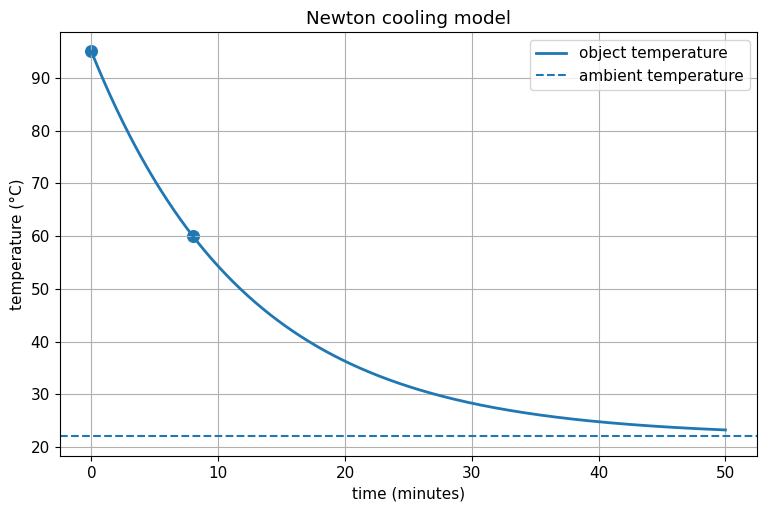

Cooling constant: 0.08160916017775068 per minute
Temperature after 20 minutes: 36.271666920464455


In [5]:
T0, Tm, T8 = 95.0, 22.0, 60.0
k_cool = -(1/8)*np.log((T8-Tm)/(T0-Tm))

t = np.linspace(0, 50, 600)
T = Tm + (T0-Tm)*np.exp(-k_cool*t)

plt.plot(t, T, linewidth=2, label="object temperature")
plt.axhline(Tm, linestyle="--", label="ambient temperature")
plt.scatter([0, 8], [T0, T8], s=70)
plt.xlabel("time (minutes)")
plt.ylabel("temperature (°C)")
plt.title("Newton cooling model")
plt.legend()
plt.show()

print("Cooling constant:", k_cool, "per minute")
print("Temperature after 20 minutes:", Tm+(T0-Tm)*np.exp(-k_cool*20))

### Practical interpretation: "within a tolerance"

Because the model approaches $T_m$ asymptotically, the question

> When does the object exactly reach room temperature?

does not have a finite answer under this idealized model.

A more practical question is

> When is the object within $\varepsilon$ degrees of the ambient temperature?

We require

$$
|T(t)-T_m|\le\varepsilon.
$$

Using

$$
|T(t)-T_m|
=
|T_0-T_m|e^{-kt},
$$

we solve

$$
|T_0-T_m|e^{-kt}\le\varepsilon.
$$

This gives

$$
\boxed{
t
\ge
\frac{1}{k}
\ln\left(
\frac{|T_0-T_m|}{\varepsilon}
\right).
}
$$

In [6]:
def cooling_explorer(T0=90.0, Tm=22.0, k=0.12, tolerance=1.0):
    t = np.linspace(0, 60, 700)
    T = Tm+(T0-Tm)*np.exp(-k*t)
    gap = abs(T0-Tm)

    if tolerance < gap:
        target_time = np.log(gap/tolerance)/k
    else:
        target_time = 0.0

    plt.plot(t, T, linewidth=2, label="object temperature")
    plt.axhline(Tm, linestyle="--", label="ambient temperature")
    plt.axvline(target_time, linestyle=":", label=f"within tolerance at t≈{target_time:.2f}")
    plt.xlabel("time")
    plt.ylabel("temperature")
    plt.title("Approach to ambient temperature")
    plt.legend()
    plt.show()

interact(
    cooling_explorer,
    T0=FloatSlider(min=0, max=120, step=2, value=90, description="$T_0$"),
    Tm=FloatSlider(min=0, max=50, step=1, value=22, description="$T_m$"),
    k=FloatSlider(min=0.02, max=0.5, step=0.02, value=0.12, description="$k$"),
    tolerance=FloatSlider(min=0.5, max=10, step=0.5, value=1, description="$\\varepsilon$")
);

interactive(children=(FloatSlider(value=90.0, description='$T_0$', max=120.0, step=2.0), FloatSlider(value=22.…

## 5. Mixing-Tank Models

### Why the state variable is the amount, not the concentration

Let

$$
A(t)=\text{amount of solute in the tank},
$$

and let

$$
V(t)=\text{volume of liquid in the tank}.
$$

The tank concentration is then

$$
\boxed{
c_{\text{tank}}(t)=\frac{A(t)}{V(t)}.
}
$$

We usually model $A(t)$ rather than concentration directly because the balance law applies naturally to **amount**:

$$
\boxed{
A'
=
\text{solute rate in}
-
\text{solute rate out}.
}
$$

The units are

$$
\frac{\text{amount}}{\text{time}}.
$$

### Constructing the inflow term

If liquid enters at rate

$$
r_{\text{in}}
\quad
\left(\frac{\text{volume}}{\text{time}}\right)
$$

with concentration

$$
c_{\text{in}}
\quad
\left(\frac{\text{amount}}{\text{volume}}\right),
$$

then

$$
\text{solute rate in}
=
r_{\text{in}}c_{\text{in}}.
$$

The units check:

$$
\frac{\text{volume}}{\text{time}}
\cdot
\frac{\text{amount}}{\text{volume}}
=
\frac{\text{amount}}{\text{time}}.
$$

### Constructing the outflow term

The crucial modeling assumption is that the tank is **well mixed**. This means the concentration of liquid leaving the tank is the same as the concentration inside the tank:

$$
c_{\text{out}}
=
\frac{A(t)}{V(t)}.
$$

If liquid leaves at rate $r_{\text{out}}$, then

$$
\text{solute rate out}
=
r_{\text{out}}\frac{A(t)}{V(t)}.
$$

Therefore the general mixing model is

$$
\boxed{
A'
=
r_{\text{in}}c_{\text{in}}
-
r_{\text{out}}\frac{A}{V(t)}.
}
$$

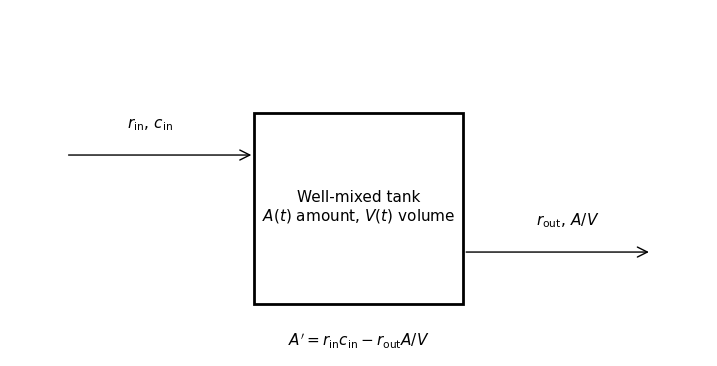

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.axis("off")

tank = Rectangle((0.35, 0.15), 0.3, 0.55, fill=False, linewidth=2)
ax.add_patch(tank)
ax.text(0.50, 0.43, "Well-mixed tank\n$A(t)$ amount, $V(t)$ volume",
        ha="center", va="center")

ax.add_patch(FancyArrowPatch((0.08, 0.58), (0.35, 0.58), arrowstyle="->", mutation_scale=18))
ax.add_patch(FancyArrowPatch((0.65, 0.30), (0.92, 0.30), arrowstyle="->", mutation_scale=18))

ax.text(0.20, 0.66, r"$r_{\rm in},\,c_{\rm in}$", ha="center")
ax.text(0.80, 0.38, r"$r_{\rm out},\,A/V$", ha="center")
ax.text(0.50, 0.03, r"$A'=r_{\rm in}c_{\rm in}-r_{\rm out}A/V$", ha="center")
plt.show()

### Constant-volume example

A 150-L tank initially contains 30 g of salt. Brine with concentration

$$
1.2\text{ g/L}
$$

enters at

$$
5\text{ L/min},
$$

and the well-mixed liquid leaves at the same rate.

Because inflow equals outflow,

$$
V(t)=150\text{ L}.
$$

The salt inflow rate is

$$
(5)(1.2)=6\text{ g/min}.
$$

The tank concentration is

$$
\frac{A}{150}\text{ g/L}.
$$

Therefore the salt outflow rate is

$$
5\left(\frac{A}{150}\right)
=
\frac{A}{30}\text{ g/min}.
$$

Hence

$$
\boxed{
A'=6-\frac{A}{30},
\qquad
A(0)=30.
}
$$

This is a linear equation:

$$
A'+\frac1{30}A=6.
$$

The equilibrium amount satisfies

$$
0=6-\frac{A^*}{30},
$$

so

$$
\boxed{
A^*=180\text{ g}.
}
$$

This also follows from equilibrium concentration:

$$
\frac{A^*}{150}
=
1.2,
$$

hence

$$
A^*=150(1.2)=180.
$$

The exact solution is

$$
\boxed{
A(t)=180+(30-180)e^{-t/30}
=
180-150e^{-t/30}.
}
$$

Thus the amount approaches 180 g, and the tank concentration approaches the inflow concentration $1.2$ g/L.

In [8]:
def constant_tank(A0=30.0, V=150.0, r=5.0, c_in=1.2, final_time=150):
    def rhs(t, A):
        return [r*c_in-r*A[0]/V]

    sol = safe_solve(rhs, (0, final_time), [A0], rtol=1e-9, atol=1e-11)
    equilibrium = V*c_in

    plt.plot(sol.t, sol.y[0], linewidth=2, label="salt amount")
    plt.axhline(equilibrium, linestyle="--", label="equilibrium amount")
    plt.xlabel("time (minutes)")
    plt.ylabel("salt (grams)")
    plt.title("Constant-volume mixing model")
    plt.legend()
    plt.show()

interact(
    constant_tank,
    A0=FloatSlider(min=0, max=400, step=10, value=30, description="$A_0$"),
    V=FloatSlider(min=50, max=300, step=10, value=150, description="$V$"),
    r=FloatSlider(min=1, max=15, step=1, value=5, description="$r$"),
    c_in=FloatSlider(min=0, max=3, step=0.1, value=1.2, description="$c_{in}$"),
    final_time=IntSlider(min=30, max=300, step=30, value=150, description="time")
);

interactive(children=(FloatSlider(value=30.0, description='$A_0$', max=400.0, step=10.0), FloatSlider(value=15…

### Variable-volume tanks

If the inflow and outflow rates differ, the liquid volume changes.

The volume balance is

$$
V'
=
r_{\text{in}}-r_{\text{out}}.
$$

Therefore

$$
\boxed{
V(t)
=
V_0+
(r_{\text{in}}-r_{\text{out}})t.
}
$$

The solute model becomes

$$
\boxed{
A'
=
r_{\text{in}}c_{\text{in}}
-
r_{\text{out}}
\frac{A}
{V_0+(r_{\text{in}}-r_{\text{out}})t}.
}
$$

The physical interval of validity must be determined before solving:

- if $r_{\text{in}}>r_{\text{out}}$, the tank may overflow;
- if $r_{\text{in}}<r_{\text{out}}$, the tank may empty;
- if $r_{\text{in}}=r_{\text{out}}$, the volume is constant.

The mathematical formula should not be interpreted beyond the time when the physical tank model ceases to make sense.

In [9]:
def variable_tank(A0=40.0, V0=100.0, rin=4.0, rout=2.0, c_in=1.0, capacity=180.0):
    net = rin-rout

    if net > 0:
        if capacity <= V0:
            print("Choose a capacity larger than the initial volume.")
            return
        physical_end = (capacity-V0)/net
        final_time = 0.98*physical_end
        end_label = "overflow time"
    elif net < 0:
        physical_end = V0/(-net)
        final_time = 0.98*physical_end
        end_label = "emptying time"
    else:
        physical_end = None
        final_time = 80
        end_label = None

    def rhs(t, A):
        V = V0+net*t
        return [rin*c_in-rout*A[0]/V]

    sol = safe_solve(rhs, (0, final_time), [A0], rtol=1e-9, atol=1e-11)
    V = V0+net*sol.t

    plt.plot(sol.t, sol.y[0], label="solute amount $A(t)$")
    plt.plot(sol.t, V, label="liquid volume $V(t)$")
    plt.xlabel("time")
    plt.ylabel("amount / volume")
    plt.title("Variable-volume mixing model")
    plt.legend()
    plt.show()

    if physical_end is not None:
        print(end_label + ":", physical_end)

interact(
    variable_tank,
    A0=FloatSlider(min=0, max=200, step=10, value=40, description="$A_0$"),
    V0=FloatSlider(min=40, max=150, step=10, value=100, description="$V_0$"),
    rin=FloatSlider(min=1, max=8, step=0.5, value=4, description="$r_{in}$"),
    rout=FloatSlider(min=1, max=8, step=0.5, value=2, description="$r_{out}$"),
    c_in=FloatSlider(min=0, max=3, step=0.1, value=1, description="$c_{in}$"),
    capacity=FloatSlider(min=120, max=300, step=10, value=180, description="capacity")
);

interactive(children=(FloatSlider(value=40.0, description='$A_0$', max=200.0, step=10.0), FloatSlider(value=10…

## 6. LR-Series Circuits

### Physical background

An LR-series circuit contains

- an inductor with inductance $L$,
- a resistor with resistance $R$,
- an applied voltage source $E(t)$,
- and a current $i(t)$.

Two voltage laws are used:

$$
V_R=Ri
$$

for the resistor, and

$$
V_L=L\frac{di}{dt}
$$

for the inductor.

Kirchhoff's voltage law states that the total voltage drop around a closed loop equals the applied voltage. Therefore

$$
V_L+V_R=E(t).
$$

Substituting the component laws gives

$$
\boxed{
L\frac{di}{dt}+Ri=E(t).
}
$$

This is a first-order linear differential equation for the current.

### Constant applied voltage

If

$$
E(t)=E_0,
$$

then

$$
Li'+Ri=E_0.
$$

Divide by $L$:

$$
i'+\frac{R}{L}i=\frac{E_0}{L}.
$$

The equilibrium or steady-state current satisfies

$$
0+\frac{R}{L}i_{\mathrm{ss}}
=
\frac{E_0}{L},
$$

so

$$
\boxed{
i_{\mathrm{ss}}=\frac{E_0}{R}.
}
$$

The complete solution is

$$
\boxed{
i(t)
=
\frac{E_0}{R}
+
\left(
i_0-\frac{E_0}{R}
\right)e^{-Rt/L}.
}
$$

The exponential term is the **transient response**; it disappears as $t$ increases.

### The time constant

Write the exponential as

$$
e^{-Rt/L}
=
e^{-t/\tau},
$$

where

$$
\boxed{
\tau=\frac{L}{R}.
}
$$

The quantity $\tau$ is called the **time constant**.

After one time constant,

$$
e^{-1}\approx0.368.
$$

Therefore only about $36.8\%$ of the initial difference from steady state remains, meaning approximately

$$
1-e^{-1}\approx0.632
$$

or $63.2\%$ of the transition has been completed.

In [10]:
def lr_explorer(L=0.8, R=6.0, E0=12.0, i0=0.0):
    tau = L/R
    t = np.linspace(0, 6*tau, 600)
    steady = E0/R
    i = steady+(i0-steady)*np.exp(-t/tau)

    plt.plot(t, i, linewidth=2, label="current")
    plt.axhline(steady, linestyle="--", label="steady-state current")
    plt.axvline(tau, linestyle=":", label=f"time constant={tau:.3f}")
    plt.xlabel("time (seconds)")
    plt.ylabel("current (amperes)")
    plt.title("Transient and steady-state current in an LR circuit")
    plt.legend()
    plt.show()

interact(
    lr_explorer,
    L=FloatSlider(min=0.1, max=3.0, step=0.1, value=0.8, description="$L$"),
    R=FloatSlider(min=1, max=20, step=1, value=6, description="$R$"),
    E0=FloatSlider(min=1, max=30, step=1, value=12, description="$E_0$"),
    i0=FloatSlider(min=-3, max=5, step=0.25, value=0, description="$i_0$")
);

interactive(children=(FloatSlider(value=0.8, description='$L$', max=3.0, min=0.1), FloatSlider(value=6.0, desc…

## 7. Model Synthesis

$$
\renewcommand{\arraystretch}{1.55}
\begin{array}{|c|c|c|c|}
\hline
\textbf{Application} &
\textbf{State variable} &
\textbf{Governing mechanism} &
\textbf{Long-term behavior}
\\
\hline
\text{Growth/decay} &
P(t) &
P'=kP &
\text{growth or decay}
\\
\hline
\text{Cooling/warming} &
T(t) &
T'=-k(T-T_m) &
T\to T_m
\\
\hline
\text{Mixing} &
A(t) &
\text{rate in}-\text{rate out} &
\text{equilibrium concentration}
\\
\hline
\text{LR circuit} &
i(t) &
Li'+Ri=E_0 &
i\to E_0/R
\\
\hline
\end{array}
$$

Although the physical settings are different, each model follows the same construction:

$$
\boxed{
\text{state variable}
\longrightarrow
\text{assumptions}
\longrightarrow
\text{rate law}
\longrightarrow
\text{differential equation}
\longrightarrow
\text{solution and interpretation}.
}
$$

## Classroom Checkpoint

In [11]:
show_31_exit_check()

### Problem 1

<IPython.core.display.Math object>

A 200-L tank receives brine at 3 L/min with concentration 2 g/L and loses mixture at the same rate. Define the state variable, construct the differential equation, find the equilibrium salt amount, and state the modeling assumption used for the output concentration.

---

### Continue to the next section when ready.

## Section 3.2: Nonlinear Models

## 1. What Makes a Population Model Nonlinear?

In Section 3.1, exponential growth was modeled by

$$
P'=rP.
$$

This is linear in the state variable $P$.

The assumption behind exponential growth is that the **per-capita growth rate**

$$
\frac{P'}{P}
$$

is constant:

$$
\frac{P'}{P}=r.
$$

In real populations, growth often changes as the population becomes crowded. Food, space, nesting sites, nutrients, or other resources may become limited.

A population model is called **density dependent** when the per-capita growth rate depends on the population size:

$$
\boxed{
P'=P f(P).
}
$$

Then

$$
\boxed{
\frac{P'}{P}=f(P).
}
$$

Because $f(P)$ depends on $P$, the resulting differential equation is generally nonlinear.

## 2. Constructing the Logistic Model

We want a simple density-dependent model with two properties:

1. when the population is very small, the per-capita growth rate should be approximately the intrinsic rate $r$;
2. when the population reaches the carrying capacity $K$, the per-capita growth rate should be zero.

Mathematically,

$$
f(0)=r
$$

and

$$
f(K)=0.
$$

The simplest function satisfying these two conditions is the straight line through the points

$$
(0,r)
\qquad\text{and}\qquad
(K,0).
$$

Its equation is

$$
\boxed{
f(P)=r\left(1-\frac{P}{K}\right).
}
$$

Therefore

$$
\frac{P'}{P}
=
r\left(1-\frac{P}{K}\right).
$$

Multiplying by $P$ gives the logistic equation

$$
\boxed{
P'
=
rP\left(1-\frac{P}{K}\right),
}
$$

where

- $r>0$ is the low-density per-capita growth rate;
- $K>0$ is the carrying capacity.

### Interpreting the logistic factor

The factor

$$
1-\frac{P}{K}
$$

measures the reduction in growth caused by crowding.

If

$$
P\ll K,
$$

then

$$
1-\frac{P}{K}\approx1,
$$

so

$$
P'\approx rP.
$$

Thus logistic growth initially resembles exponential growth.

If

$$
0<P<K,
$$

then

$$
P'>0,
$$

so the population grows.

If

$$
P=K,
$$

then

$$
P'=0.
$$

If

$$
P>K,
$$

then

$$
P'<0,
$$

so the model predicts a decrease toward the carrying capacity.

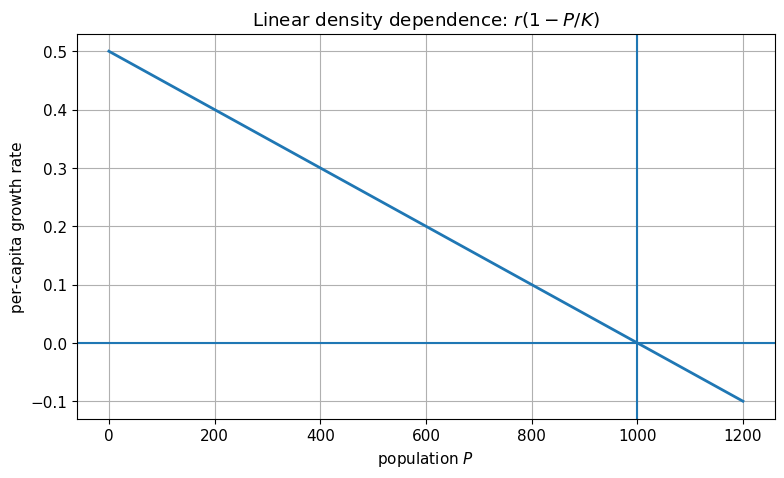

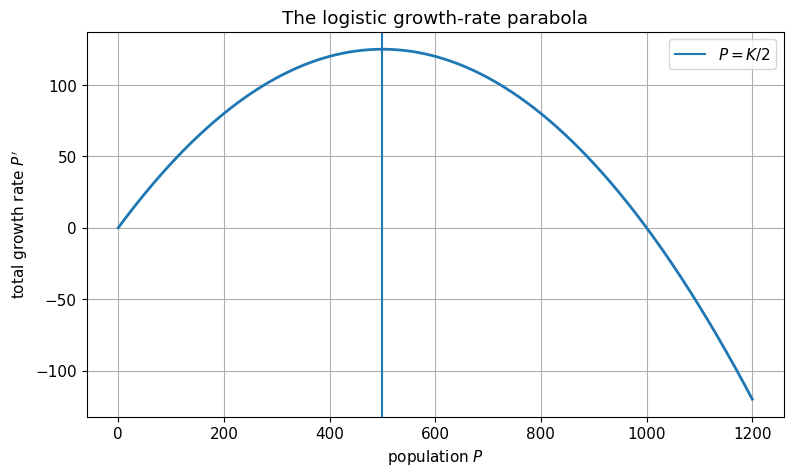

In [12]:
P = np.linspace(0, 1200, 500)
r, K = 0.5, 1000
per_capita = r*(1-P/K)
total_growth = P*per_capita

plt.figure(figsize=(9,5))
plt.plot(P, per_capita, linewidth=2)
plt.axhline(0)
plt.axvline(K)
plt.xlabel("population $P$")
plt.ylabel("per-capita growth rate")
plt.title(r"Linear density dependence: $r(1-P/K)$")
plt.show()

plt.figure(figsize=(9,5))
plt.plot(P, total_growth, linewidth=2)
plt.axvline(K/2, label="$P=K/2$")
plt.xlabel("population $P$")
plt.ylabel("total growth rate $P'$")
plt.title("The logistic growth-rate parabola")
plt.legend()
plt.show()

## 3. Equilibria and Phase-Line Interpretation

The equilibria satisfy

$$
P'=0.
$$

Therefore

$$
rP\left(1-\frac{P}{K}\right)=0.
$$

Since $r>0$,

$$
P=0
$$

or

$$
P=K.
$$

Thus

$$
\boxed{
P=0
\qquad\text{and}\qquad
P=K
}
$$

are equilibrium solutions.

For positive populations,

$$
\renewcommand{\arraystretch}{1.55}
\begin{array}{|c|c|c|}
\hline
\textbf{Population range} & \textbf{Sign of }P' & \textbf{Behavior} \\
\hline
0<P<K & + & P\text{ increases} \\
\hline
P>K & - & P\text{ decreases} \\
\hline
\end{array}
$$

Therefore:

- $P=0$ is unstable for positive perturbations;
- $P=K$ attracts nearby positive populations and is asymptotically stable.

### Explicit logistic solution

From Section 2.2, for

$$
P(0)=P_0>0,
$$

the logistic solution is

$$
\boxed{
P(t)
=
\frac{K}
{
1+
\left(
\frac{K-P_0}{P_0}
\right)e^{-rt}
}.
}
$$

In this chapter, our main emphasis is not re-deriving the separation calculation. Instead, we use the solution to interpret the model and connect its parameters to data and long-term behavior.

In [13]:
def logistic_explorer(P0=100.0, r=0.4, K=1000.0, final_time=30):
    t = np.linspace(0, final_time, 700)
    A = (K-P0)/P0
    denom = 1 + A*np.exp(-r*t)

    if np.any(np.abs(denom) < 1e-8):
        print("The selected parameters create a denominator near zero.")
        return

    P = K/denom

    plt.plot(t, P, linewidth=2, label="population")
    plt.axhline(K, label="carrying capacity")
    plt.axhline(K/2, label="$K/2$")
    plt.scatter([0], [P0], s=70)
    plt.xlabel("time")
    plt.ylabel("$P(t)$")
    plt.title("Logistic population trajectories")
    plt.legend()
    plt.show()

interact(
    logistic_explorer,
    P0=FloatSlider(min=20, max=1600, step=20, value=100, description="$P_0$"),
    r=FloatSlider(min=0.05, max=1.0, step=0.05, value=0.4, description="$r$"),
    K=FloatSlider(min=200, max=1500, step=50, value=1000, description="$K$"),
    final_time=IntSlider(min=10, max=60, step=5, value=30, description="time")
);

interactive(children=(FloatSlider(value=100.0, description='$P_0$', max=1600.0, min=20.0, step=20.0), FloatSli…

## 4. Concavity and the Fastest-Growth Point

The logistic curve is not increasing at the same rate throughout its growth.

Start with

$$
P'
=
rP\left(1-\frac{P}{K}\right).
$$

Differentiate both sides with respect to time.

Using the product rule,

$$
P''
=
rP'\left(1-\frac{P}{K}\right)
+
rP\left(-\frac{P'}{K}\right).
$$

Factor out $rP'$:

$$
P''
=
rP'
\left[
1-\frac{P}{K}-\frac{P}{K}
\right].
$$

Therefore

$$
\boxed{
P''
=
rP'
\left(
1-\frac{2P}{K}
\right).
}
$$

For a growing logistic solution with

$$
0<P<K,
$$

we have

$$
P'>0.
$$

Therefore the sign of $P''$ is determined by

$$
1-\frac{2P}{K}.
$$

If

$$
P<\frac{K}{2},
$$

then

$$
P''>0,
$$

so the graph is concave up.

If

$$
P>\frac{K}{2},
$$

then

$$
P''<0,
$$

so the graph is concave down.

Thus the inflection point occurs when

$$
\boxed{
P=\frac{K}{2}.
}
$$

This is also the population level where the **total population growth rate** is largest.

### Why is the growth rate largest at $K/2$?

Treat the logistic growth term as a function of population:

$$
G(P)
=
rP\left(1-\frac{P}{K}\right).
$$

Expand:

$$
G(P)
=
rP-\frac{r}{K}P^2.
$$

This is a downward-opening parabola.

Differentiate with respect to $P$:

$$
G'(P)
=
r-\frac{2r}{K}P.
$$

Set

$$
G'(P)=0:
$$

$$
r-\frac{2r}{K}P=0.
$$

Since $r>0$,

$$
1-\frac{2P}{K}=0,
$$

so

$$
\boxed{
P=\frac{K}{2}.
}
$$

The maximum growth rate is therefore

$$
G\left(\frac{K}{2}\right)
=
r\frac{K}{2}
\left(1-\frac12\right)
=
\boxed{
\frac{rK}{4}.
}
$$

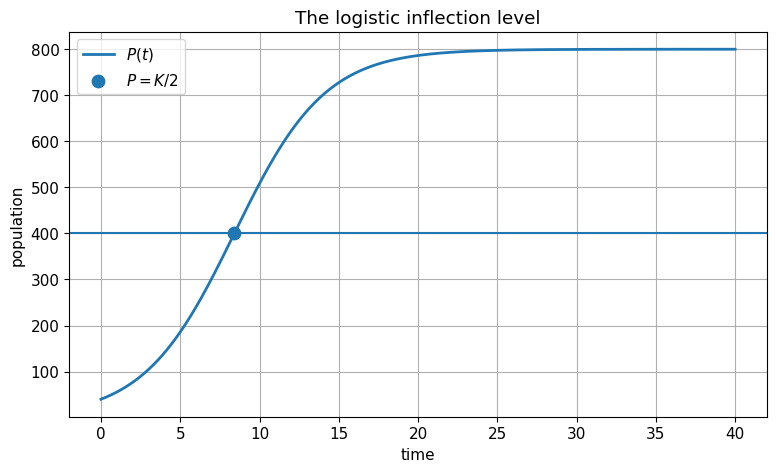

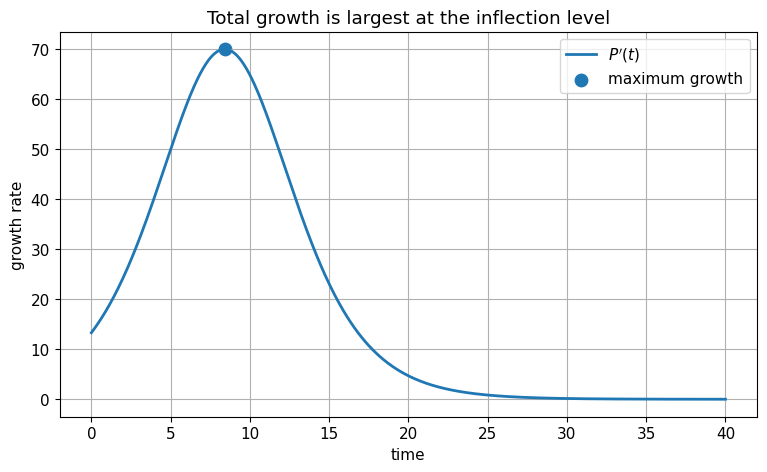

In [14]:
r, K, P0 = 0.35, 800, 40
t = np.linspace(0, 40, 700)
A = (K-P0)/P0
P = K/(1+A*np.exp(-r*t))
Pprime = r*P*(1-P/K)
Psecond = r*Pprime*(1-2*P/K)

plt.figure(figsize=(9,5))
plt.plot(t, P, linewidth=2, label="$P(t)$")
idx = np.argmin(np.abs(P-K/2))
plt.scatter([t[idx]], [P[idx]], s=80, label="$P=K/2$")
plt.axhline(K/2)
plt.xlabel("time")
plt.ylabel("population")
plt.title("The logistic inflection level")
plt.legend()
plt.show()

plt.figure(figsize=(9,5))
plt.plot(t, Pprime, linewidth=2, label="$P'(t)$")
plt.scatter([t[idx]], [Pprime[idx]], s=80, label="maximum growth")
plt.xlabel("time")
plt.ylabel("growth rate")
plt.title("Total growth is largest at the inflection level")
plt.legend()
plt.show()

## 5. Estimating the Logistic Growth Rate from Data

Suppose $K$ and $P_0$ are known and an observation

$$
P(t_1)=P_1
$$

is available.

The logistic formula is

$$
P_1
=
\frac{K}{1+Ae^{-rt_1}},
$$

where

$$
A
=
\frac{K-P_0}{P_0}.
$$

Invert the equation:

$$
\frac{K}{P_1}
=
1+Ae^{-rt_1}.
$$

Subtract $1$:

$$
\frac{K}{P_1}-1
=
Ae^{-rt_1}.
$$

Therefore

$$
e^{-rt_1}
=
\frac{
K/P_1-1
}{A}.
$$

Take logarithms:

$$
-rt_1
=
\ln\left(
\frac{K/P_1-1}{A}
\right).
$$

Hence

$$
\boxed{
r
=
\frac{1}{t_1}
\ln\left(
\frac{A}{K/P_1-1}
\right).
}
$$

This is an example of **parameter calibration**: observed data are used to estimate a parameter in the model.

Estimated r = 0.385792118148308


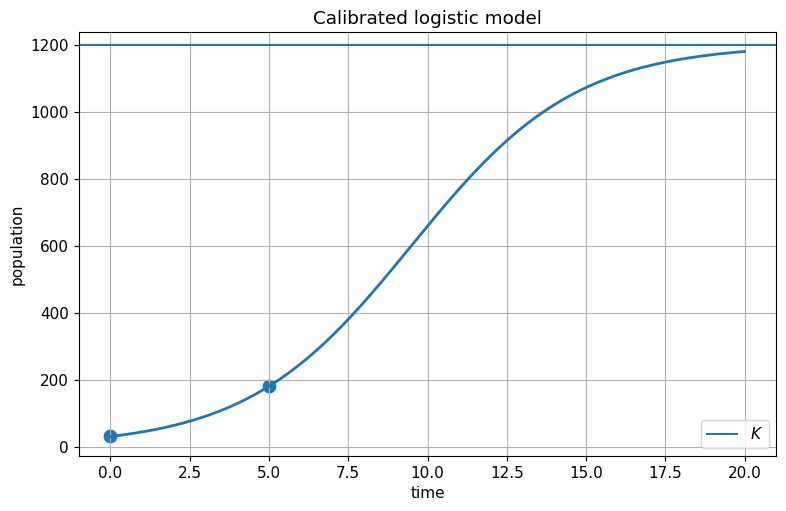

In [15]:
K, P0, t1, P1 = 1200, 30, 5, 180
A = (K-P0)/P0
r_est = (1/t1)*np.log(A/(K/P1-1))
print("Estimated r =", r_est)

t = np.linspace(0, 20, 600)
P = K/(1+A*np.exp(-r_est*t))
plt.plot(t, P, linewidth=2)
plt.scatter([0,t1],[P0,P1],s=80)
plt.axhline(K, label="$K$")
plt.xlabel("time")
plt.ylabel("population")
plt.title("Calibrated logistic model")
plt.legend()
plt.show()

## 6. Logistic Growth with Constant Harvesting

Suppose a population follows logistic growth but individuals are removed at a constant rate

$$
h>0.
$$

Examples include a fixed fishing quota, a fixed removal program, or a constant extraction rate.

The model becomes

$$
\boxed{
P'
=
rP\left(1-\frac{P}{K}\right)-h.
}
$$

The term

$$
rP\left(1-\frac{P}{K}\right)
$$

is the natural biological growth rate, while

$$
h
$$

is the removal rate.

The population increases only when natural growth exceeds harvesting.

### Finding harvested equilibria

At equilibrium,

$$
0
=
rP\left(1-\frac{P}{K}\right)-h.
$$

Therefore

$$
rP-\frac{r}{K}P^2=h.
$$

Rearrange:

$$
P^2-KP+\frac{hK}{r}=0.
$$

Using the quadratic formula,

$$
P
=
\frac{
K\pm
\sqrt{
K^2-\frac{4hK}{r}
}
}{2}.
$$

Factor $K^2$ inside the square root:

$$
\boxed{
P_{\pm}
=
\frac{K}{2}
\left(
1
\pm
\sqrt{
1-\frac{4h}{rK}
}
\right).
}
$$

Real positive equilibria exist only when

$$
1-\frac{4h}{rK}\ge0.
$$

Thus

$$
\boxed{
h\le\frac{rK}{4}.
}
$$

### Why does the threshold equal $rK/4$?

Earlier we found that the unharvested logistic population has maximum natural growth rate

$$
\boxed{
G_{\max}=\frac{rK}{4}.
}
$$

A constant harvest can be balanced by natural population growth only if the harvest does not exceed the largest growth rate the population is capable of producing.

Therefore:

- if
  $$
  0<h<\frac{rK}{4},
  $$
  there are two positive equilibria;
- if
  $$
  h=\frac{rK}{4},
  $$
  the two equilibria merge at
  $$
  P=\frac{K}{2};
  $$
- if
  $$
  h>\frac{rK}{4},
  $$
  the harvest exceeds natural growth at every positive population level, so the model predicts decline toward extinction.

A modeling caution is important: the differential equation with constant subtraction $-h$ would mathematically continue into negative populations after crossing $P=0$. Negative populations are not physically meaningful, so the model should be stopped at extinction or modified near zero.

In [16]:
def harvest_explorer(r=0.5, K=1000.0, h=80.0, P0=700.0, final_time=40):
    P_grid = np.linspace(0, 1.2*K, 600)
    natural = r*P_grid*(1-P_grid/K)
    net = natural-h
    hcrit = r*K/4

    plt.figure(figsize=(9,5))
    plt.plot(P_grid, natural, linewidth=2, label="natural logistic growth")
    plt.axhline(h, label="constant harvest")
    plt.axvline(K/2, label="$K/2$")
    plt.xlabel("$P$")
    plt.ylabel("rate")
    plt.title("Harvest equilibria are intersections of growth and harvest")
    plt.legend()
    plt.show()

    def rhs(t, z):
        return [r*z[0]*(1-z[0]/K)-h]

    def extinction_event(t, z):
        return z[0]
    extinction_event.terminal = True
    extinction_event.direction = -1

    sol = solve_ivp(
        rhs, (0, final_time), [P0],
        events=extinction_event, dense_output=True,
        max_step=0.05, rtol=1e-9, atol=1e-11
    )

    tt = np.linspace(0, sol.t[-1], 600)
    PP = sol.sol(tt)[0]

    plt.figure(figsize=(9,5))
    plt.plot(tt, PP, linewidth=2)
    plt.axhline(0)
    plt.xlabel("time")
    plt.ylabel("$P(t)$")
    plt.title("Population trajectory under constant harvesting")
    plt.show()

    print("Critical harvest =", hcrit)

    if h < hcrit:
        disc = 1-4*h/(r*K)
        low = K*(1-np.sqrt(disc))/2
        high = K*(1+np.sqrt(disc))/2
        print("Lower equilibrium:", low)
        print("Upper equilibrium:", high)
    elif np.isclose(h, hcrit):
        print("One repeated equilibrium at K/2.")
    else:
        print("No positive equilibrium.")

interact(
    harvest_explorer,
    r=FloatSlider(min=0.1,max=1.0,step=0.05,value=0.5,description="$r$"),
    K=FloatSlider(min=200,max=2000,step=100,value=1000,description="$K$"),
    h=FloatSlider(min=0,max=300,step=10,value=80,description="$h$"),
    P0=FloatSlider(min=10,max=1800,step=10,value=700,description="$P_0$"),
    final_time=IntSlider(min=10,max=100,step=5,value=40,description="time")
);

interactive(children=(FloatSlider(value=0.5, description='$r$', max=1.0, min=0.1, step=0.05), FloatSlider(valu…

## 7. Optional Comparison: Logistic and Gompertz Growth

The logistic model assumes that the per-capita growth rate decreases **linearly** with population:

$$
\frac{P'}{P}
=
r\left(1-\frac{P}{K}\right).
$$

Another saturating model is the Gompertz equation

$$
\boxed{
P'
=
rP\ln\left(\frac{K}{P}\right).
}
$$

Both models can approach the same carrying capacity $K$, but their growth curves have different shapes.

The logistic curve has its inflection level at

$$
P=\frac{K}{2},
$$

while the Gompertz curve is asymmetric and has a different inflection level.

This comparison illustrates an important modeling principle: different biological assumptions can lead to different differential equations even when they predict the same long-term carrying capacity.

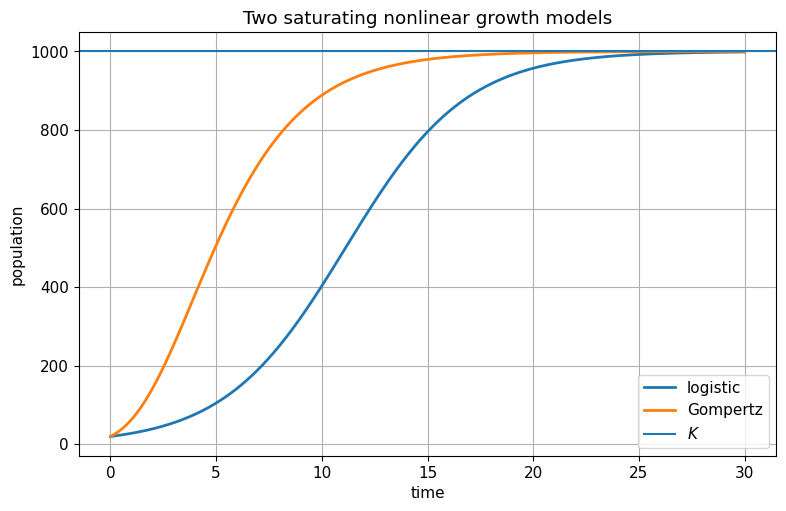

In [17]:
K, P0, r = 1000, 20, 0.35
t = np.linspace(0, 30, 700)

logistic = K/(1+((K-P0)/P0)*np.exp(-r*t))
gompertz = K*np.exp(np.log(P0/K)*np.exp(-r*t))

plt.plot(t, logistic, linewidth=2, label="logistic")
plt.plot(t, gompertz, linewidth=2, label="Gompertz")
plt.axhline(K, label="$K$")
plt.xlabel("time")
plt.ylabel("population")
plt.title("Two saturating nonlinear growth models")
plt.legend()
plt.show()

## 8. Second-Order Chemical Reactions

### Law of mass action

Consider a chemical reaction in which two reactants combine to form a product.

After appropriate stoichiometric scaling, suppose the initial reactant amounts are

$$
\alpha
\qquad\text{and}\qquad
\beta.
$$

Let

$$
X(t)
=
\text{amount of product formed by time }t.
$$

If one unit of each reactant is consumed for each unit of product formed, then the amounts of reactants remaining are

$$
\alpha-X
$$

and

$$
\beta-X.
$$

The **law of mass action** states that the reaction rate is proportional to the product of the available reactant amounts.

Therefore

$$
X'
\propto
(\alpha-X)(\beta-X).
$$

Introducing a positive reaction-rate constant $k$ gives

$$
\boxed{
X'
=
k(\alpha-X)(\beta-X).
}
$$

Because the right-hand side contains a product involving $X$, this is a nonlinear differential equation.

### Physical interval and limiting reactant

The model must satisfy

$$
\alpha-X\ge0
$$

and

$$
\beta-X\ge0.
$$

Therefore

$$
X\le\alpha
$$

and

$$
X\le\beta.
$$

Assuming no product is initially present,

$$
X\ge0.
$$

Hence the physically meaningful interval is

$$
\boxed{
0\le X\le\min(\alpha,\beta).
}
$$

The smaller initial reactant amount is the **limiting reactant**.

If

$$
\beta<\alpha,
$$

then the reaction cannot produce more than $\beta$ units of product, because the second reactant is exhausted first.

This physical restriction should be identified before interpreting any numerical or analytical solution.

### Separation when $\alpha\ne\beta$

For non-equilibrium solutions,

$$
\frac{dX}{(\alpha-X)(\beta-X)}
=
k\,dt.
$$

Use partial fractions:

$$
\frac{1}{(\alpha-X)(\beta-X)}
=
\frac{1}{\beta-\alpha}
\left[
\frac{1}{\alpha-X}
-
\frac{1}{\beta-X}
\right].
$$

Integrating gives

$$
\frac{1}{\beta-\alpha}
\ln\left|
\frac{\beta-X}{\alpha-X}
\right|
=
kt+C.
$$

This implicit relation can be solved for $X(t)$ after an initial condition is supplied.

Even when we use numerical simulation, the analytical form helps explain why the solution approaches the limiting reactant amount rather than growing without bound.

In [18]:
def reaction_explorer(alpha=60.0, beta=40.0, k=0.002, X0=0.0, final_time=80):
    physical_limit = min(alpha, beta)

    if not (0 <= X0 <= physical_limit):
        print("Choose X0 inside the physical interval.")
        return

    def rhs(t, X):
        return [k*(alpha-X[0])*(beta-X[0])]

    sol = safe_solve(rhs, (0, final_time), [X0], rtol=1e-9, atol=1e-11)

    plt.plot(sol.t, sol.y[0], linewidth=2, label="product $X(t)$")
    plt.axhline(physical_limit, label="limiting amount")
    plt.xlabel("time")
    plt.ylabel("product amount")
    plt.title("Second-order reaction")
    plt.legend()
    plt.show()

interact(
    reaction_explorer,
    alpha=FloatSlider(min=10,max=100,step=5,value=60,description="$\\alpha$"),
    beta=FloatSlider(min=10,max=100,step=5,value=40,description="$\\beta$"),
    k=FloatSlider(min=0.0005,max=0.01,step=0.0005,value=0.002,description="$k$"),
    X0=FloatSlider(min=0,max=20,step=1,value=0,description="$X_0$"),
    final_time=IntSlider(min=20,max=200,step=10,value=80,description="time")
);

interactive(children=(FloatSlider(value=60.0, description='$\\alpha$', min=10.0, step=5.0), FloatSlider(value=…

## 9. Model Synthesis

$$
\renewcommand{\arraystretch}{1.5}
\begin{array}{|c|c|c|c|}
\hline
\textbf{Model} &
\textbf{State} &
\textbf{Nonlinear mechanism} &
\textbf{Key restriction / threshold}
\\
\hline
\text{Logistic} &
P(t) &
P(1-P/K) &
P=K\text{ carrying capacity}
\\
\hline
\text{Harvesting} &
P(t) &
P(1-P/K)-h &
h\le rK/4
\\
\hline
\text{Reaction} &
X(t) &
(\alpha-X)(\beta-X) &
0\le X\le\min(\alpha,\beta)
\\
\hline
\end{array}
$$

The nonlinear terms are not added merely to make the mathematics more complicated. Each one represents a specific mechanism: crowding, removal, or interaction between available reactants.

## Classroom Checkpoint

In [19]:
show_32_exit_check()

### Problem 1

<IPython.core.display.Math object>

Find the maximum sustainable constant harvest and explain why this value is the threshold.

---

### Continue to the next section when ready.

## Section 3.3: Modeling with Systems of First-Order Differential Equations

## 1. Why Do We Need Systems of Differential Equations?

A single differential equation is appropriate when one state variable is enough to describe the changing system.

Many applications contain several quantities that change **simultaneously** and influence one another.

Examples include:

- several chemical species in a reaction;
- several tanks exchanging solute;
- parent and daughter radioactive isotopes;
- prey and predator populations;
- competing biological species;
- currents in an electrical network.

If the state variables are

$$
x_1(t),x_2(t),\ldots,x_n(t),
$$

then a first-order system has the form

$$
\boxed{
\begin{aligned}
x_1'&=f_1(t,x_1,\ldots,x_n),\\
x_2'&=f_2(t,x_1,\ldots,x_n),\\
&\vdots\\
x_n'&=f_n(t,x_1,\ldots,x_n).
\end{aligned}
}
$$

Using vector notation,

$$
\boxed{
\mathbf{x}'=\mathbf{f}(t,\mathbf{x}),
\qquad
\mathbf{x}(t_0)=\mathbf{x}_0.
}
$$

The vector

$$
\mathbf{x}(t)
=
\begin{bmatrix}
x_1(t)\\
\vdots\\
x_n(t)
\end{bmatrix}
$$

is called the **state vector**.

### Linear and nonlinear systems

A first-order system is linear if it can be written as

$$
\boxed{
\mathbf{x}'
=
A(t)\mathbf{x}
+
\mathbf{g}(t),
}
$$

where the entries of the matrix $A(t)$ and the forcing vector $\mathbf{g}(t)$ depend only on the independent variable.

For example,

$$
\begin{aligned}
x'&=-2x+y,\\
y'&=3x-4y
\end{aligned}
$$

is linear.

In contrast,

$$
\begin{aligned}
x'&=x-xy,\\
y'&=-y+xy
\end{aligned}
$$

is nonlinear because the product

$$
xy
$$

multiplies two state variables.

## 2. Compartment Models and the Balance Principle

A **compartment model** divides a system into identifiable states or locations and tracks the amount in each compartment.

For every compartment, use the balance law

$$
\boxed{
\text{rate of change}
=
\text{total inflow}
-
\text{total outflow}
+
\text{internal production}
-
\text{internal loss}.
}
$$

A particularly important bookkeeping rule is:

> An internal flow leaving one compartment must appear with a negative sign in the source equation and a positive sign in the destination equation.

For example, if material moves from compartment 1 to compartment 2 at rate $q(t)$, then the contribution is

$$
\boxed{
\begin{aligned}
x_1'&:\quad -q(t),\\
x_2'&:\quad +q(t).
\end{aligned}
}
$$

When these two equations are added, the internal flow cancels.

This cancellation is the mathematical reason conservation laws often appear naturally in compartment models.

## 3. Radioactive Decay Chain

### Model construction

Suppose a radioactive parent isotope $X_1$ decays into a radioactive daughter isotope $X_2$, which then decays into a stable product $X_3$:

$$
\boxed{
X_1
\longrightarrow
X_2
\longrightarrow
X_3.
}
$$

Let

- $X_1(t)$ = amount of parent isotope;
- $X_2(t)$ = amount of daughter isotope;
- $X_3(t)$ = amount of stable product.

Let

$$
k_1>0
$$

be the decay constant for the first transition and

$$
k_2>0
$$

the decay constant for the second.

Radioactive decay is proportional to the amount currently present.

### Constructing each equation

#### Parent isotope

The parent has no inflow and decays at rate

$$
k_1X_1.
$$

Therefore

$$
\boxed{
X_1'=-k_1X_1.
}
$$

#### Daughter isotope

The daughter receives material from the parent at rate

$$
k_1X_1
$$

and loses material through its own decay at rate

$$
k_2X_2.
$$

Therefore

$$
\boxed{
X_2'
=
k_1X_1-k_2X_2.
}
$$

#### Stable product

The stable product receives all material that leaves the daughter and has no further decay:

$$
\boxed{
X_3'=k_2X_2.
}
$$

Hence the system is

$$
\boxed{
\begin{aligned}
X_1'&=-k_1X_1,\\
X_2'&=k_1X_1-k_2X_2,\\
X_3'&=k_2X_2.
\end{aligned}
}
$$

### Conservation of total amount

Add the three equations:

$$
X_1'+X_2'+X_3'
=
-k_1X_1
+
(k_1X_1-k_2X_2)
+
k_2X_2.
$$

The internal transfer terms cancel:

$$
X_1'+X_2'+X_3'=0.
$$

Therefore

$$
\frac{d}{dt}
(X_1+X_2+X_3)=0.
$$

Hence

$$
\boxed{
X_1(t)+X_2(t)+X_3(t)
=
X_1(0)+X_2(0)+X_3(0).
}
$$

The model conserves total material because nothing enters or leaves the three-compartment system.

### Solving the first two equations sequentially

The first equation is independent of $X_2$ and $X_3$:

$$
X_1'=-k_1X_1.
$$

Therefore

$$
\boxed{
X_1(t)=X_{10}e^{-k_1t}.
}
$$

Substitute this into the daughter equation:

$$
X_2'+k_2X_2
=
k_1X_{10}e^{-k_1t}.
$$

This is a first-order linear equation.

Using the integrating factor

$$
e^{k_2t},
$$

we obtain

$$
\left(e^{k_2t}X_2\right)'
=
k_1X_{10}e^{(k_2-k_1)t}.
$$

If

$$
k_1\ne k_2,
$$

integration gives

$$
\boxed{
X_2(t)
=
X_{20}e^{-k_2t}
+
\frac{k_1X_{10}}{k_2-k_1}
\left(
e^{-k_1t}-e^{-k_2t}
\right).
}
$$

Finally, $X_3(t)$ can be found from conservation:

$$
\boxed{
X_3(t)
=
X_{\mathrm{total}}
-
X_1(t)
-
X_2(t).
}
$$

In [20]:
def decay_chain(k1=0.12, k2=0.35, X10=100.0, X20=0.0, X30=0.0, final_time=60):
    def rhs(t, X):
        x1, x2, x3 = X
        return [-k1*x1, k1*x1-k2*x2, k2*x2]

    sol = safe_solve(
        rhs, (0, final_time), [X10, X20, X30],
        rtol=1e-9, atol=1e-11
    )

    plt.plot(sol.t, sol.y[0], linewidth=2, label="parent")
    plt.plot(sol.t, sol.y[1], linewidth=2, label="daughter")
    plt.plot(sol.t, sol.y[2], linewidth=2, label="stable product")
    plt.xlabel("time")
    plt.ylabel("amount")
    plt.title("Radioactive decay chain")
    plt.legend()
    plt.show()

    total = sol.y.sum(axis=0)
    print("Maximum total-amount drift:", np.max(np.abs(total-total[0])))

interact(
    decay_chain,
    k1=FloatSlider(min=0.02,max=0.5,step=0.02,value=0.12,description="$k_1$"),
    k2=FloatSlider(min=0.02,max=0.8,step=0.02,value=0.35,description="$k_2$"),
    X10=FloatSlider(min=10,max=200,step=10,value=100,description="$X_{10}$"),
    X20=FloatSlider(min=0,max=100,step=5,value=0,description="$X_{20}$"),
    X30=FloatSlider(min=0,max=100,step=5,value=0,description="$X_{30}$"),
    final_time=IntSlider(min=10,max=150,step=10,value=60,description="time")
);

interactive(children=(FloatSlider(value=0.12, description='$k_1$', max=0.5, min=0.02, step=0.02), FloatSlider(…

### Why can the daughter population initially increase?

Although $X_2$ is radioactive and decays, it is also being produced from $X_1$.

Its equation is

$$
X_2'=k_1X_1-k_2X_2.
$$

Therefore

$$
X_2'>0
$$

whenever

$$
k_1X_1>k_2X_2.
$$

The daughter amount reaches a local maximum when production and loss balance:

$$
\boxed{
k_1X_1=k_2X_2.
}
$$

This is a useful modeling lesson: knowing that a compartment has a loss mechanism does not automatically imply that its total amount is decreasing.

## 4. Two Connected Mixing Tanks

### State variables and concentrations

Let

$$
x_1(t)
=
\text{solute amount in Tank 1},
$$

and

$$
x_2(t)
=
\text{solute amount in Tank 2}.
$$

Suppose both tanks have constant volume $V$ and are perfectly mixed.

Then the concentrations are

$$
\frac{x_1}{V}
\qquad\text{and}\qquad
\frac{x_2}{V}.
$$

Let

$$
q_{12}
$$

be the liquid flow rate from Tank 1 to Tank 2, and let

$$
q_{21}
$$

be the flow rate from Tank 2 to Tank 1.

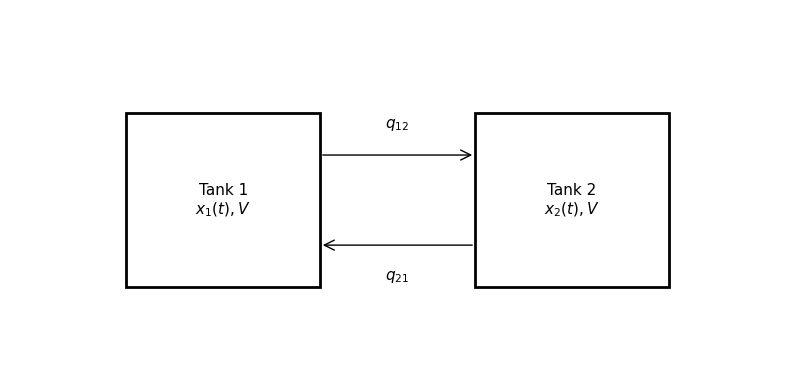

In [21]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.axis("off")

tank1 = Rectangle((0.15, 0.2), 0.25, 0.5, fill=False, linewidth=2)
tank2 = Rectangle((0.60, 0.2), 0.25, 0.5, fill=False, linewidth=2)
ax.add_patch(tank1)
ax.add_patch(tank2)

ax.text(0.275, 0.45, "Tank 1\n$x_1(t),V$", ha="center", va="center")
ax.text(0.725, 0.45, "Tank 2\n$x_2(t),V$", ha="center", va="center")

ax.add_patch(FancyArrowPatch((0.40, 0.58), (0.60, 0.58),
                             arrowstyle="->", mutation_scale=18))
ax.add_patch(FancyArrowPatch((0.60, 0.32), (0.40, 0.32),
                             arrowstyle="->", mutation_scale=18))
ax.text(0.50, 0.66, r"$q_{12}$", ha="center")
ax.text(0.50, 0.22, r"$q_{21}$", ha="center")
plt.show()

### Constructing the Tank 1 equation

Tank 1 loses solute through the flow to Tank 2.

The outgoing solute rate is

$$
q_{12}\frac{x_1}{V}.
$$

Tank 1 receives solute from Tank 2 at rate

$$
q_{21}\frac{x_2}{V}.
$$

Therefore

$$
\boxed{
x_1'
=
-q_{12}\frac{x_1}{V}
+
q_{21}\frac{x_2}{V}.
}
$$

### Constructing the Tank 2 equation

The same flow $q_{12}$ that is negative in the Tank 1 equation is positive in the Tank 2 equation:

$$
+q_{12}\frac{x_1}{V}.
$$

Likewise, the flow from Tank 2 back to Tank 1 contributes

$$
-q_{21}\frac{x_2}{V}.
$$

Hence

$$
\boxed{
x_2'
=
q_{12}\frac{x_1}{V}
-
q_{21}\frac{x_2}{V}.
}
$$

### Conservation and equilibrium

Add the equations:

$$
x_1'+x_2'=0.
$$

Thus

$$
\boxed{
x_1+x_2=S
}
$$

is constant, where $S$ is the total amount of solute.

At equilibrium,

$$
q_{12}\frac{x_1^*}{V}
=
q_{21}\frac{x_2^*}{V}.
$$

Therefore

$$
q_{12}x_1^*
=
q_{21}x_2^*.
$$

Together with

$$
x_1^*+x_2^*=S,
$$

we obtain

$$
\boxed{
x_1^*
=
S\frac{q_{21}}{q_{12}+q_{21}},
}
$$

and

$$
\boxed{
x_2^*
=
S\frac{q_{12}}{q_{12}+q_{21}}.
}
$$

Notice that the tank receiving the larger one-way transfer rate at equilibrium holds the larger share of total solute.

In [22]:
def two_tanks(V=100.0, q12=6.0, q21=3.0, x10=80.0, x20=10.0, final_time=120):
    def rhs(t, x):
        x1, x2 = x
        return [
            -q12*x1/V+q21*x2/V,
            q12*x1/V-q21*x2/V
        ]

    sol = safe_solve(rhs, (0, final_time), [x10, x20],
                     rtol=1e-9, atol=1e-11)

    S = x10+x20
    x1eq = S*q21/(q12+q21)
    x2eq = S*q12/(q12+q21)

    plt.plot(sol.t, sol.y[0], linewidth=2, label="Tank 1")
    plt.plot(sol.t, sol.y[1], linewidth=2, label="Tank 2")
    plt.axhline(x1eq, label="Tank 1 equilibrium")
    plt.axhline(x2eq, label="Tank 2 equilibrium")
    plt.xlabel("time")
    plt.ylabel("solute amount")
    plt.title("Exchange between two tanks")
    plt.legend()
    plt.show()

    total = sol.y[0]+sol.y[1]
    print("Maximum conservation error:", np.max(np.abs(total-total[0])))

interact(
    two_tanks,
    V=FloatSlider(min=40,max=200,step=10,value=100,description="$V$"),
    q12=FloatSlider(min=1,max=15,step=1,value=6,description="$q_{12}$"),
    q21=FloatSlider(min=1,max=15,step=1,value=3,description="$q_{21}$"),
    x10=FloatSlider(min=0,max=200,step=10,value=80,description="$x_1(0)$"),
    x20=FloatSlider(min=0,max=200,step=10,value=10,description="$x_2(0)$"),
    final_time=IntSlider(min=20,max=300,step=20,value=120,description="time")
);

interactive(children=(FloatSlider(value=100.0, description='$V$', max=200.0, min=40.0, step=10.0), FloatSlider…

## 5. Predator–Prey Modeling

Let

$$
x(t)
=
\text{prey population},
$$

and

$$
y(t)
=
\text{predator population}.
$$

The classical Lotka–Volterra model is constructed from four idealized assumptions.

### Assumption 1: prey growth without predators

If predators are absent, prey grow exponentially:

$$
x'=\alpha x,
\qquad
\alpha>0.
$$

### Assumption 2: predator decline without prey

If prey are absent, predators decline exponentially:

$$
y'=-\gamma y,
\qquad
\gamma>0.
$$

### Assumption 3: encounter rate

If prey and predators mix randomly, the encounter rate is modeled as proportional to

$$
xy.
$$

Thus predator encounters reduce prey at rate

$$
\beta xy,
\qquad
\beta>0.
$$

### Assumption 4: predator reproduction

Successful encounters contribute to predator growth at rate

$$
\delta xy,
\qquad
\delta>0.
$$

Combining these mechanisms gives

$$
\boxed{
\begin{aligned}
x'&=\alpha x-\beta xy,\\
y'&=\delta xy-\gamma y.
\end{aligned}
}
$$

### Why the system is nonlinear

Factor the equations:

$$
x'
=
x(\alpha-\beta y),
$$

$$
y'
=
y(\delta x-\gamma).
$$

The product term

$$
xy
$$

makes the system nonlinear.

The signs also have direct biological interpretations:

$$
x'>0
\quad\Longleftrightarrow\quad
y<\frac{\alpha}{\beta},
$$

so prey increase when the predator population is below the threshold

$$
\frac{\alpha}{\beta}.
$$

Similarly,

$$
y'>0
\quad\Longleftrightarrow\quad
x>\frac{\gamma}{\delta},
$$

so predators increase when the prey population is above the threshold

$$
\frac{\gamma}{\delta}.
$$

### Equilibria

At equilibrium,

$$
x'=0
\qquad\text{and}\qquad
y'=0.
$$

From

$$
x(\alpha-\beta y)=0,
$$

we have

$$
x=0
\qquad\text{or}\qquad
y=\frac{\alpha}{\beta}.
$$

From

$$
y(\delta x-\gamma)=0,
$$

we have

$$
y=0
\qquad\text{or}\qquad
x=\frac{\gamma}{\delta}.
$$

The two simultaneous equilibria are therefore

$$
\boxed{(0,0)}
$$

and

$$
\boxed{
\left(
\frac{\gamma}{\delta},
\frac{\alpha}{\beta}
\right).
}
$$

The positive equilibrium represents a state at which prey and predator populations are both instantaneously constant.

### Time plot versus phase-plane plot

A **time plot** shows each population as a function of time:

$$
t\longmapsto x(t),
\qquad
t\longmapsto y(t).
$$

It answers questions such as:

- When does the prey population peak?
- When does the predator population peak?
- What is the period of the oscillation?

A **phase-plane plot** eliminates time from the axes and plots

$$
\boxed{
(x(t),y(t)).
}
$$

Each point in the phase plane represents the complete biological state at one instant.

The direction of motion along the phase-plane curve shows how the joint state evolves.

In [23]:
def predator_prey(alpha=1.0, beta=0.1, delta=0.075, gamma=1.5,
                  x0=20.0, y0=8.0, final_time=40):
    def rhs(t, z):
        x, y = z
        return [
            alpha*x-beta*x*y,
            delta*x*y-gamma*y
        ]

    sol = safe_solve(rhs, (0, final_time), [x0, y0],
                     rtol=1e-9, atol=1e-11)

    plt.figure(figsize=(9,5))
    plt.plot(sol.t, sol.y[0], linewidth=2, label="prey")
    plt.plot(sol.t, sol.y[1], linewidth=2, label="predator")
    plt.xlabel("time")
    plt.ylabel("population")
    plt.title("Predator and prey time series")
    plt.legend()
    plt.show()

    plt.figure(figsize=(7,6))
    plt.plot(sol.y[0], sol.y[1], linewidth=2)
    plt.scatter([x0], [y0], s=70, label="initial state")
    plt.scatter([gamma/delta], [alpha/beta], s=70, label="positive equilibrium")
    plt.xlabel("prey $x$")
    plt.ylabel("predator $y$")
    plt.title("Phase-plane trajectory")
    plt.legend()
    plt.show()

    if np.all(sol.y[0] > 0) and np.all(sol.y[1] > 0):
        H = (
            delta*sol.y[0]
            - gamma*np.log(sol.y[0])
            + beta*sol.y[1]
            - alpha*np.log(sol.y[1])
        )
        print("Maximum first-integral drift:", np.max(np.abs(H-H[0])))

interact(
    predator_prey,
    alpha=FloatSlider(min=0.2,max=2.0,step=0.1,value=1.0,description="$\\alpha$"),
    beta=FloatSlider(min=0.02,max=0.3,step=0.01,value=0.1,description="$\\beta$"),
    delta=FloatSlider(min=0.02,max=0.2,step=0.005,value=0.075,description="$\\delta$"),
    gamma=FloatSlider(min=0.2,max=3.0,step=0.1,value=1.5,description="$\\gamma$"),
    x0=FloatSlider(min=2,max=60,step=1,value=20,description="$x_0$"),
    y0=FloatSlider(min=2,max=40,step=1,value=8,description="$y_0$"),
    final_time=IntSlider(min=10,max=100,step=5,value=40,description="time")
);

interactive(children=(FloatSlider(value=1.0, description='$\\alpha$', max=2.0, min=0.2), FloatSlider(value=0.1…

### Why does the predator peak occur after the prey peak?

The prey population changes sign when

$$
x'=x(\alpha-\beta y)=0.
$$

For a positive prey population, a prey extremum occurs when

$$
\boxed{
y=\frac{\alpha}{\beta}.
}
$$

The predator population changes sign when

$$
y'=y(\delta x-\gamma)=0.
$$

For a positive predator population, a predator extremum occurs when

$$
\boxed{
x=\frac{\gamma}{\delta}.
}
$$

Along a typical cycle, prey increase first while predator abundance is relatively low. The larger prey population then supports predator growth. Predator abundance rises later, increasing pressure on the prey. Consequently, the prey peak typically occurs before the predator peak.

This delay is called a **phase lag**.

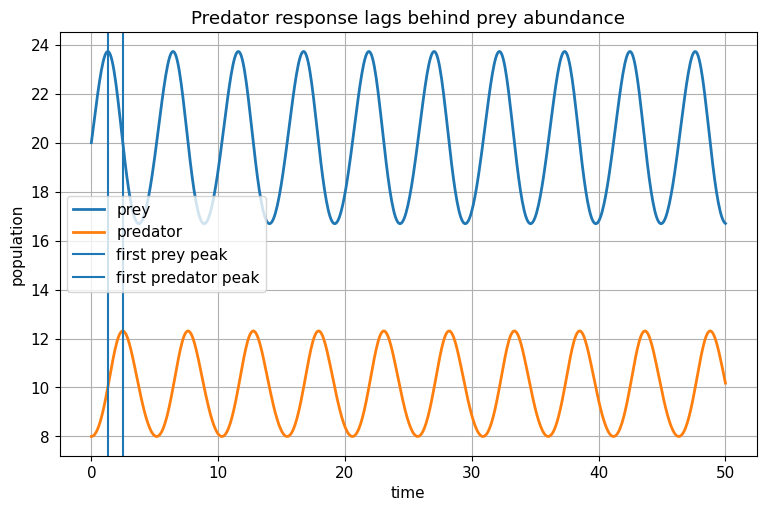

First prey peak time: 1.2875536480686696
First predator peak time: 2.503576537911302


In [24]:
alpha, beta, delta, gamma = 1.0, 0.1, 0.075, 1.5

def rhs_pp(t, z):
    x, y = z
    return [alpha*x-beta*x*y, delta*x*y-gamma*y]

sol = safe_solve(rhs_pp, (0, 50), [20, 8], rtol=1e-10, atol=1e-12)

# Find local maxima rather than simply the largest displayed value.
def first_local_max_index(values):
    for j in range(1, len(values)-1):
        if values[j-1] < values[j] and values[j] > values[j+1]:
            return j
    return None

prey_idx = first_local_max_index(sol.y[0])
pred_idx = first_local_max_index(sol.y[1])

plt.plot(sol.t, sol.y[0], linewidth=2, label="prey")
plt.plot(sol.t, sol.y[1], linewidth=2, label="predator")

if prey_idx is not None:
    plt.axvline(sol.t[prey_idx], label="first prey peak")
if pred_idx is not None:
    plt.axvline(sol.t[pred_idx], label="first predator peak")

plt.xlabel("time")
plt.ylabel("population")
plt.title("Predator response lags behind prey abundance")
plt.legend()
plt.show()

if prey_idx is not None:
    print("First prey peak time:", sol.t[prey_idx])
if pred_idx is not None:
    print("First predator peak time:", sol.t[pred_idx])

### A conserved quantity in the ideal Lotka–Volterra model

For positive populations, define

$$
H(x,y)
=
\delta x
-\gamma\ln x
+\beta y
-\alpha\ln y.
$$

Differentiate along a solution:

$$
\frac{dH}{dt}
=
\delta x'
-\gamma\frac{x'}{x}
+\beta y'
-\alpha\frac{y'}{y}.
$$

Using

$$
\frac{x'}{x}
=
\alpha-\beta y
$$

and

$$
\frac{y'}{y}
=
\delta x-\gamma,
$$

we can factor the derivative as

$$
\frac{dH}{dt}
=
(\alpha-\beta y)(\delta x-\gamma)
+
(\delta x-\gamma)(\beta y-\alpha).
$$

The two terms cancel:

$$
\boxed{
\frac{dH}{dt}=0.
}
$$

Therefore

$$
\boxed{
H(x(t),y(t))=\text{constant}
}
$$

along positive non-equilibrium trajectories of the ideal model.

This conservation property explains the closed phase-plane curves of the classical Lotka–Volterra equations. It is a special feature of the idealized model and generally disappears when more realistic effects are added.

## 6. Logistic Competition Between Two Species

The logistic equation models one population limited by its own crowding.

For two species that compete for overlapping resources, the effective crowding experienced by each species can include both populations.

A common model is

$$
\boxed{
x'
=
r_1x
\left(
1-\frac{x+\alpha_{12}y}{K_1}
\right),
}
$$

$$
\boxed{
y'
=
r_2y
\left(
1-\frac{y+\alpha_{21}x}{K_2}
\right).
}
$$

Here

- $K_1$ and $K_2$ are the single-species carrying capacities;
- $\alpha_{12}$ measures the competitive effect of species $y$ on species $x$;
- $\alpha_{21}$ measures the competitive effect of species $x$ on species $y$.

For species $x$, one individual of species $y$ contributes an effective crowding amount $\alpha_{12}$ relative to one individual of species $x$.

### Nullclines

A **nullcline** is a curve on which one derivative is zero.

For

$$
x'
=
r_1x
\left(
1-\frac{x+\alpha_{12}y}{K_1}
\right),
$$

the $x$-nullclines are

$$
x=0
$$

and

$$
\boxed{
x+\alpha_{12}y=K_1.
}
$$

For the second species,

$$
y=0
$$

and

$$
\boxed{
\alpha_{21}x+y=K_2.
}
$$

The nonzero nullclines can be written as

$$
y=\frac{K_1-x}{\alpha_{12}}
$$

and

$$
y=K_2-\alpha_{21}x.
$$

Their positions in the phase plane help determine whether:

- species $x$ excludes species $y$;
- species $y$ excludes species $x$;
- both species coexist;
- or the long-term outcome depends on the initial populations.

### Interior coexistence equilibrium

If both species are positive at equilibrium, solve

$$
x+\alpha_{12}y=K_1
$$

and

$$
\alpha_{21}x+y=K_2.
$$

From the first equation,

$$
x=K_1-\alpha_{12}y.
$$

Substitute into the second:

$$
\alpha_{21}(K_1-\alpha_{12}y)+y=K_2.
$$

Therefore

$$
(1-\alpha_{12}\alpha_{21})y
=
K_2-\alpha_{21}K_1.
$$

If

$$
1-\alpha_{12}\alpha_{21}\ne0,
$$

then

$$
\boxed{
y^*
=
\frac{
K_2-\alpha_{21}K_1
}{
1-\alpha_{12}\alpha_{21}
}.
}
$$

Similarly,

$$
\boxed{
x^*
=
\frac{
K_1-\alpha_{12}K_2
}{
1-\alpha_{12}\alpha_{21}
}.
}
$$

These formulas describe a biologically meaningful coexistence equilibrium only when

$$
x^*>0
\qquad\text{and}\qquad
y^*>0.
$$

In [25]:
def competition_explorer(r1=0.6, r2=0.5, K1=100.0, K2=100.0,
                         a12=0.7, a21=0.6, x0=20.0, y0=25.0, final_time=80):
    def rhs(t, z):
        x, y = z
        return [
            r1*x*(1-(x+a12*y)/K1),
            r2*y*(1-(y+a21*x)/K2)
        ]

    sol = safe_solve(rhs, (0, final_time), [x0, y0],
                     rtol=1e-9, atol=1e-11)

    plt.figure(figsize=(9,5))
    plt.plot(sol.t, sol.y[0], linewidth=2, label="species $x$")
    plt.plot(sol.t, sol.y[1], linewidth=2, label="species $y$")
    plt.xlabel("time")
    plt.ylabel("population")
    plt.title("Competition dynamics")
    plt.legend()
    plt.show()

    x_max = max(K1, K2/a21)*1.15
    x_grid = np.linspace(0, x_max, 400)
    y_null_1 = (K1-x_grid)/a12
    y_null_2 = K2-a21*x_grid

    mask1 = y_null_1 >= 0
    mask2 = y_null_2 >= 0

    plt.figure(figsize=(7,6))
    plt.plot(x_grid[mask1], y_null_1[mask1], linewidth=2, label="$x'=0$")
    plt.plot(x_grid[mask2], y_null_2[mask2], linewidth=2, label="$y'=0$")
    plt.plot(sol.y[0], sol.y[1], linewidth=2, label="trajectory")
    plt.scatter([x0], [y0], s=70, label="initial state")
    plt.xlim(0, x_max)
    plt.ylim(0, max(K2, K1/a12)*1.1)
    plt.xlabel("$x$")
    plt.ylabel("$y$")
    plt.title("Competition nullclines and trajectory")
    plt.legend()
    plt.show()

interact(
    competition_explorer,
    r1=FloatSlider(min=0.1,max=1.2,step=0.1,value=0.6,description="$r_1$"),
    r2=FloatSlider(min=0.1,max=1.2,step=0.1,value=0.5,description="$r_2$"),
    K1=FloatSlider(min=40,max=200,step=10,value=100,description="$K_1$"),
    K2=FloatSlider(min=40,max=200,step=10,value=100,description="$K_2$"),
    a12=FloatSlider(min=0.1,max=2.0,step=0.1,value=0.7,description="$\\alpha_{12}$"),
    a21=FloatSlider(min=0.1,max=2.0,step=0.1,value=0.6,description="$\\alpha_{21}$"),
    x0=FloatSlider(min=2,max=150,step=2,value=20,description="$x_0$"),
    y0=FloatSlider(min=2,max=150,step=2,value=25,description="$y_0$"),
    final_time=IntSlider(min=20,max=150,step=10,value=80,description="time")
);

interactive(children=(FloatSlider(value=0.6, description='$r_1$', max=1.2, min=0.1), FloatSlider(value=0.5, de…

## 7. Short Extension: Electrical Networks

A circuit containing several interacting currents naturally leads to a system of differential equations.

The modeling ingredients are:

- **Kirchhoff's current law:** current entering a junction equals current leaving the junction;
- **Kirchhoff's voltage law:** the signed voltage changes around a closed loop sum to zero;
- resistor law:
  $$
  V_R=Ri;
  $$
- inductor law:
  $$
  V_L=L\frac{di}{dt}.
  $$

The main modeling task is to choose independent current variables and use a consistent sign convention.

Detailed solution methods for linear systems will be developed later in the course.

## 8. Model Synthesis

$$
\renewcommand{\arraystretch}{1.5}
\begin{array}{|c|c|c|}
\hline
\textbf{Model} & \textbf{Coupling mechanism} & \textbf{Key structural idea} \\
\hline
\text{Decay chain} & \text{material transfer} & \text{total amount conserved} \\
\hline
\text{Connected tanks} & \text{fluid exchange} & \text{internal flows cancel} \\
\hline
\text{Predator--prey} & xy\text{ encounters} & \text{nonlinear cyclic interaction} \\
\hline
\text{Competition} & \text{shared crowding} & \text{nullcline geometry} \\
\hline
\end{array}
$$

For every system, construct one equation at a time:

$$
\boxed{
\text{Choose a state}
\longrightarrow
\text{list its gains}
\longrightarrow
\text{list its losses}
\longrightarrow
\text{write its differential equation}.
}
$$

## Classroom Checkpoint

In [26]:
show_33_exit_check()

### Problem 1

<IPython.core.display.Math object>

Find the positive equilibrium and show how each equilibrium condition is obtained.